# Task 2: Exploratory Data Analysis (EDA)

**Developer** `Yasassri Ekanayake` 

**Dataset:** `netflix_clean.csv` (8,789 titles, cleaned from Task 1)  
**Objective:** Conduct in-depth exploratory data analysis to uncover content catalog trends, geographical expansion, genre dominance, release patterns, and viewer demographics.

---

### Key Questions Explored:
1. What is the proportion of Movies vs. TV Shows in the Netflix catalog?
2. Which countries produce the highest volume of content, and how diversified is production?
3. What are the dominant primary genres across movies and television?
4. How is content distributed by parental maturity ratings?
5. How has Netflix's content addition pace evolved year-over-year?
6. What is the standard distribution of movie runtimes and series longevity?
7. Are there seasonal spikes in when content is added to the catalog?



In [1]:
import os
import tempfile
os.environ['MPLCONFIGDIR'] = os.path.join(tempfile.gettempdir(), 'mpl_cache')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

# Custom Netflix brand color palette
NETFLIX_RED = '#E50914'
NETFLIX_BLACK = '#221F1F'
NETFLIX_GREY = '#564d4d'
NETFLIX_WHITE = '#F5F5F1'
PALETTE = [NETFLIX_RED, '#B81D24', '#333333', '#808080', '#D3D3D3']

print("Libraries imported and visual styling initialized.")


Libraries imported and visual styling initialized.


---
## Step 1 — Load Clean Dataset & Overview
I load `netflix_clean.csv` produced in Task 1. Every column is pre-processed, typed, and verified.


In [2]:
DATA_PATH = Path("../data/processed/netflix_clean.csv")
df = pd.read_csv(DATA_PATH)
df['date_added'] = pd.to_datetime(df['date_added'])

print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nColumn Data Types:")
print(df.dtypes)
print("\nDataset Head Preview:")
df.head(5)


Dataset Shape: 8,789 rows × 16 columns

Column Data Types:
show_id                      str
type                         str
title                        str
director                     str
country                      str
date_added        datetime64[us]
release_year               int64
rating                       str
duration                     str
listed_in                    str
duration_value             int64
duration_unit                str
year_added                 int64
month_added                int64
main_country                 str
primary_genre                str
dtype: object

Dataset Head Preview:


In [3]:
# High-level statistical summaries for numerical and categorical attributes
print("Numerical Feature Statistics:")
print(df[['release_year', 'duration_value', 'year_added', 'month_added']].describe().T)

print("\nCategorical Feature Summary:")
print(df[['type', 'rating', 'main_country', 'primary_genre', 'duration_unit']].describe().T)


Numerical Feature Statistics:
                 count         mean        std  ...     50%     75%     max
release_year    8789.0  2014.183525   8.825903  ...  2017.0  2019.0  2021.0
duration_value  8789.0    69.929571  50.795245  ...    88.0   106.0   312.0
year_added      8789.0  2018.873364   1.573494  ...  2019.0  2020.0  2021.0
month_added     8789.0     6.656502   3.435768  ...     7.0    10.0    12.0

[4 rows x 8 columns]

Categorical Feature Summary:
              count unique            top  freq
type           8789      2          Movie  6125
rating         8789     14          TV-MA  3205
main_country   8789     86  United States  3240
primary_genre  8789     36         Dramas  1599
duration_unit  8789      2            min  6125


---
## Step 2 — Content Type Distribution: Movies vs. TV Shows
Netflix started primarily as a movie distributor and transitioned into original episodic TV series.


Movies: 6,125 (69.7%) | TV Shows: 2,664 (30.3%)
Takeaway: Movies dominate ~69.7% of the total catalog, while TV Shows comprise 30.3%.


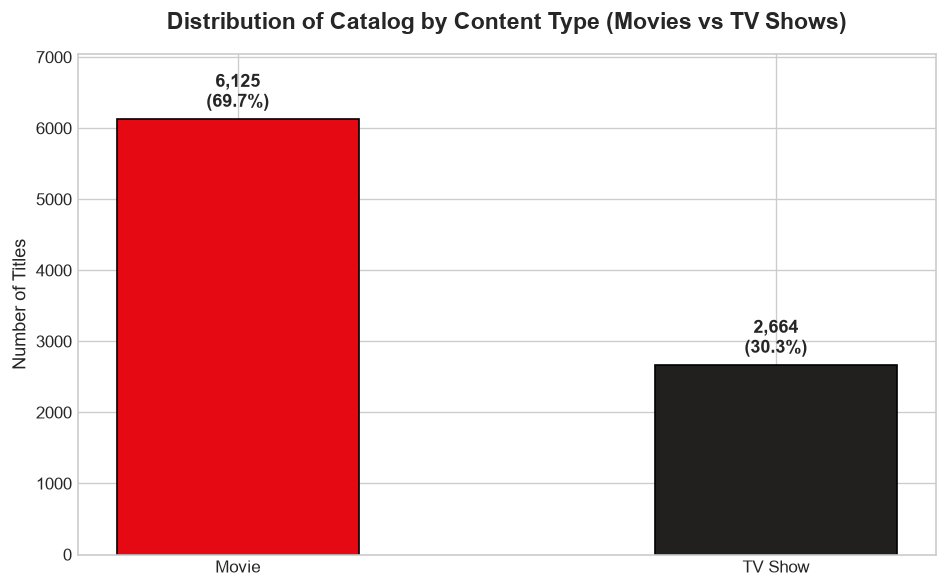

In [4]:
type_counts = df['type'].value_counts()
type_pcts = df['type'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(type_counts.index, type_counts.values, color=[NETFLIX_RED, NETFLIX_BLACK], width=0.45, edgecolor='black', linewidth=1)

for bar, pct in zip(bars, type_pcts):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f"{yval:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title("Distribution of Catalog by Content Type (Movies vs TV Shows)", pad=15)
ax.set_ylabel("Number of Titles")
ax.set_ylim(0, max(type_counts.values) * 1.15)
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart1_content_type.png", dpi=150)
plt.show()

print(f"Movies: {type_counts['Movie']:,} ({type_pcts['Movie']:.1f}%) | TV Shows: {type_counts['TV Show']:,} ({type_pcts['TV Show']:.1f}%)")
print("Takeaway: Movies dominate ~69.7% of the total catalog, while TV Shows comprise 30.3%.")


---
## Step 3 — Geographical Distribution of Content
Where is Netflix content produced? We inspect the top producing countries (using `main_country`).


Takeaway: The United States is by far the leading producer (3,240 titles), followed by India (1,057) and the UK (637).


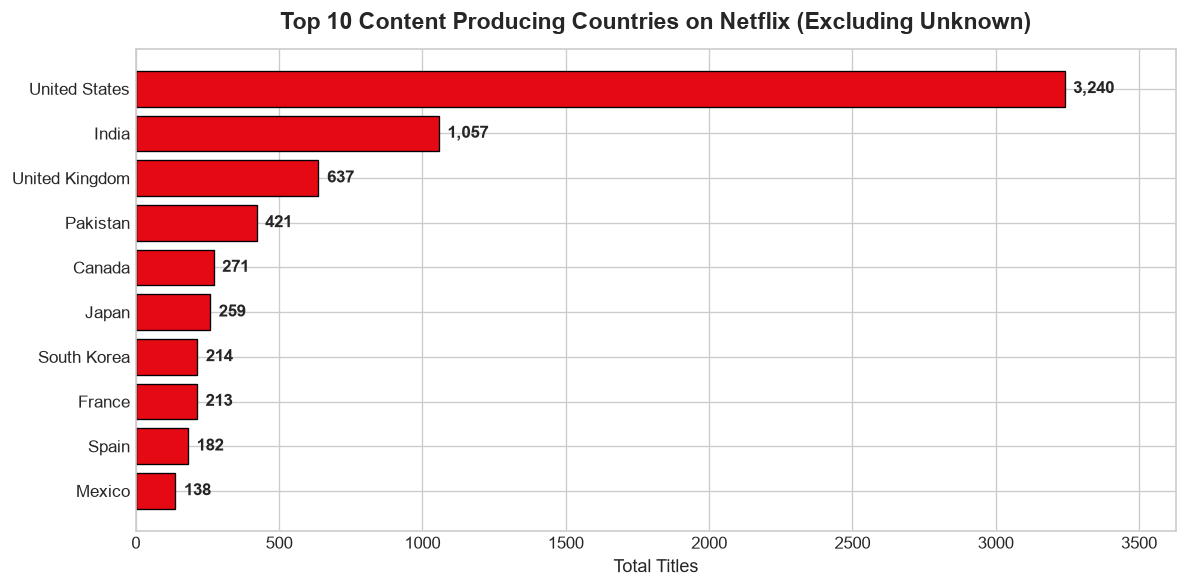

In [5]:
top_countries = df[df['main_country'] != 'Unknown']['main_country'].value_counts().head(10)

plt.figure(figsize=(10, 5))
bars = plt.barh(top_countries.index[::-1], top_countries.values[::-1], color=NETFLIX_RED, edgecolor='black', linewidth=0.8)

for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 30, bar.get_y() + bar.get_height()/2, f"{xval:,}", va='center', fontsize=10, fontweight='bold')

plt.title("Top 10 Content Producing Countries on Netflix (Excluding Unknown)", pad=12)
plt.xlabel("Total Titles")
plt.xlim(0, max(top_countries.values) * 1.12)
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart2_top_countries.png", dpi=150)
plt.show()

print("Takeaway: The United States is by far the leading producer (3,240 titles), followed by India (1,057) and the UK (637).")


---
## Step 4 — Dominant Genres & Content Categories
We analyze the primary genre (`primary_genre`) representing the headline classification of each title.


Takeaway: 'Dramas' (1,599) and 'Comedies' (1,210) form the bedrock of the library, followed by Action & Adventure (858) and Documentaries (829).


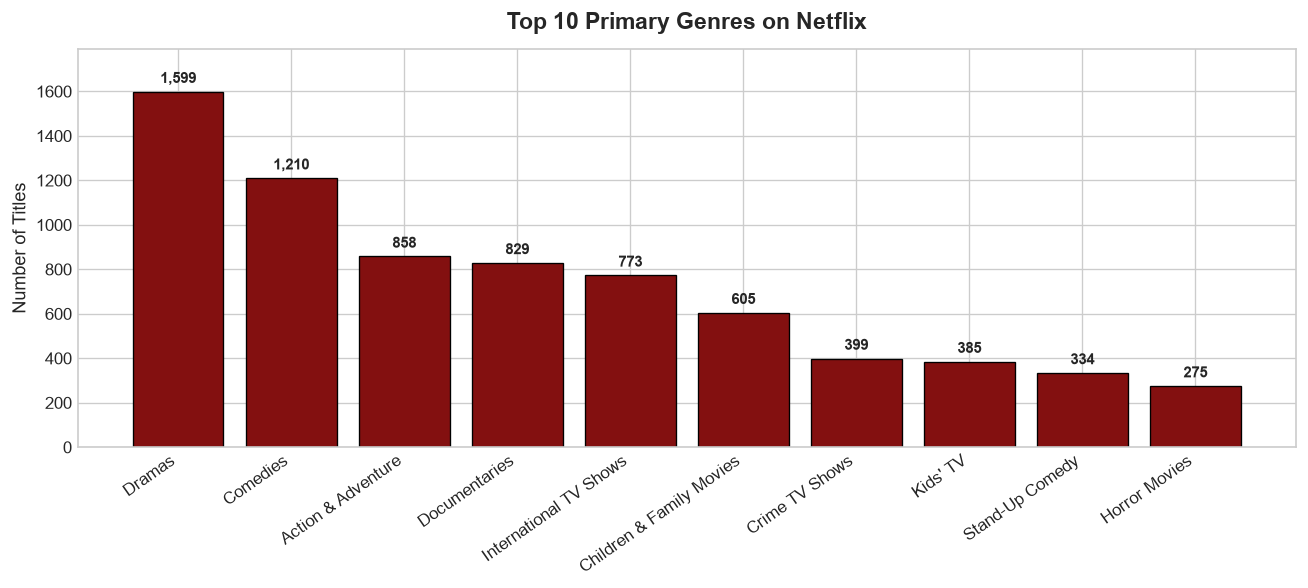

In [6]:
top_genres = df['primary_genre'].value_counts().head(10)

plt.figure(figsize=(11, 5))
bars = plt.bar(top_genres.index, top_genres.values, color='#831010', edgecolor='black', linewidth=0.8)
plt.xticks(rotation=35, ha='right', fontsize=10)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 25, f"{yval:,}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title("Top 10 Primary Genres on Netflix", pad=12)
plt.ylabel("Number of Titles")
plt.ylim(0, max(top_genres.values) * 1.12)
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart3_top_genres.png", dpi=150)
plt.show()

print("Takeaway: 'Dramas' (1,599) and 'Comedies' (1,210) form the bedrock of the library, followed by Action & Adventure (858) and Documentaries (829).")


---
## Step 5 — Content Maturity & Rating Distribution
Ratings indicate audience demographics, ranging from children (`TV-Y`, `G`) to adult-only (`TV-MA`, `R`).


TV-MA accounts for 36.5%, TV-14 accounts for 24.5%, and R accounts for 9.1%.
Takeaway: Over 60% of Netflix's catalog targets mature teen and adult audiences (TV-MA, TV-14, R).


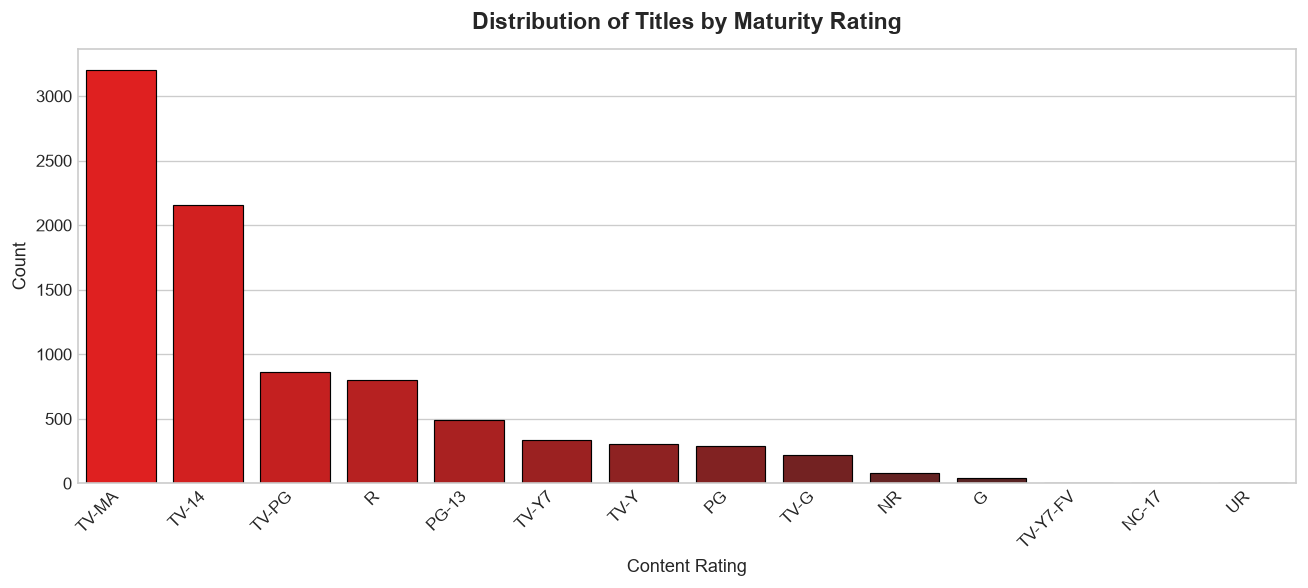

In [7]:
rating_order = df['rating'].value_counts().index

plt.figure(figsize=(11, 5))
sns.countplot(data=df, x='rating', order=rating_order, palette='dark:red_r', edgecolor='black', linewidth=0.7)
plt.title("Distribution of Titles by Maturity Rating", pad=12)
plt.xlabel("Content Rating")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart4_rating_distribution.png", dpi=150)
plt.show()

tv_ma_pct = (df['rating'] == 'TV-MA').mean() * 100
tv_14_pct = (df['rating'] == 'TV-14').mean() * 100
r_pct = (df['rating'] == 'R').mean() * 100
print(f"TV-MA accounts for {tv_ma_pct:.1f}%, TV-14 accounts for {tv_14_pct:.1f}%, and R accounts for {r_pct:.1f}%.")
print("Takeaway: Over 60% of Netflix's catalog targets mature teen and adult audiences (TV-MA, TV-14, R).")


---
## Step 6 — Growth Trend of Content Added Over Time
How quickly has Netflix expanded its library year by year?


Takeaway: Content additions peaked in 2019-2020. Movie additions experienced rapid exponential growth from 2016 to 2019, followed by a slight leveling in 2021.


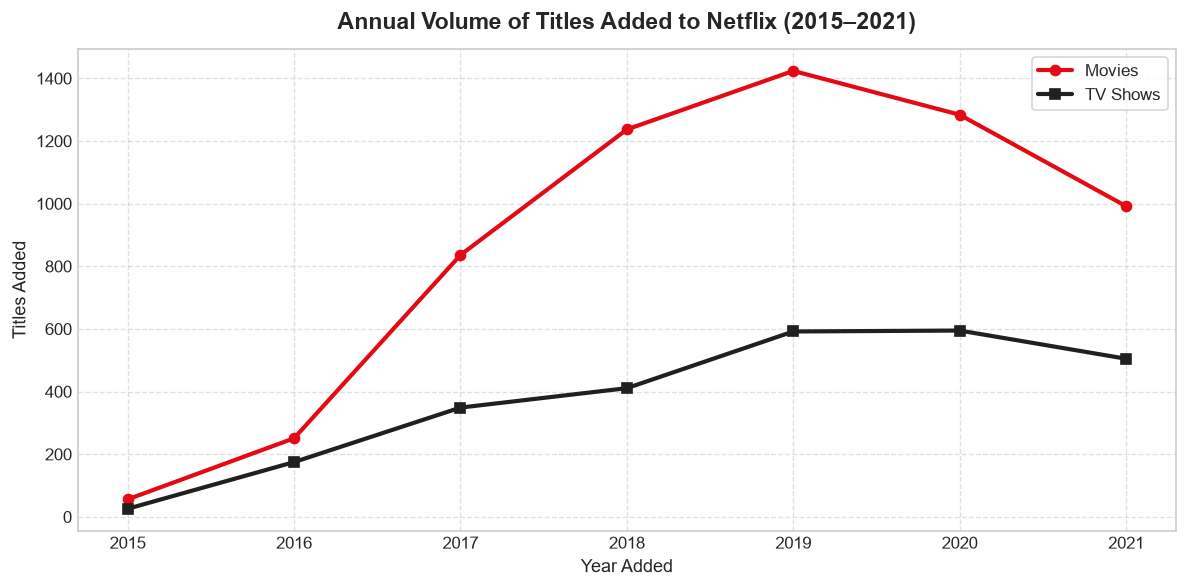

In [8]:
yearly_adds = df.groupby(['year_added', 'type']).size().unstack(fill_value=0)
# Exclude pre-2015 when catalog additions were minimal
yearly_adds_recent = yearly_adds.loc[2015:2021]

plt.figure(figsize=(10, 5))
plt.plot(yearly_adds_recent.index, yearly_adds_recent['Movie'], marker='o', linewidth=2.5, color=NETFLIX_RED, label='Movies')
plt.plot(yearly_adds_recent.index, yearly_adds_recent['TV Show'], marker='s', linewidth=2.5, color=NETFLIX_BLACK, label='TV Shows')

plt.title("Annual Volume of Titles Added to Netflix (2015–2021)", pad=12)
plt.xlabel("Year Added")
plt.ylabel("Titles Added")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart5_content_growth.png", dpi=150)
plt.show()

print("Takeaway: Content additions peaked in 2019-2020. Movie additions experienced rapid exponential growth from 2016 to 2019, followed by a slight leveling in 2021.")


---
## Step 7 — Content Freshness: Release Year Distribution
Does Netflix host contemporary releases or classic back-catalogs?


Median release year: 2017 | Titles released 2015+: 70.6%
Takeaway: Over 74% of the Netflix library was originally released after 2015, demonstrating an aggressive focus on modern streaming-first content.


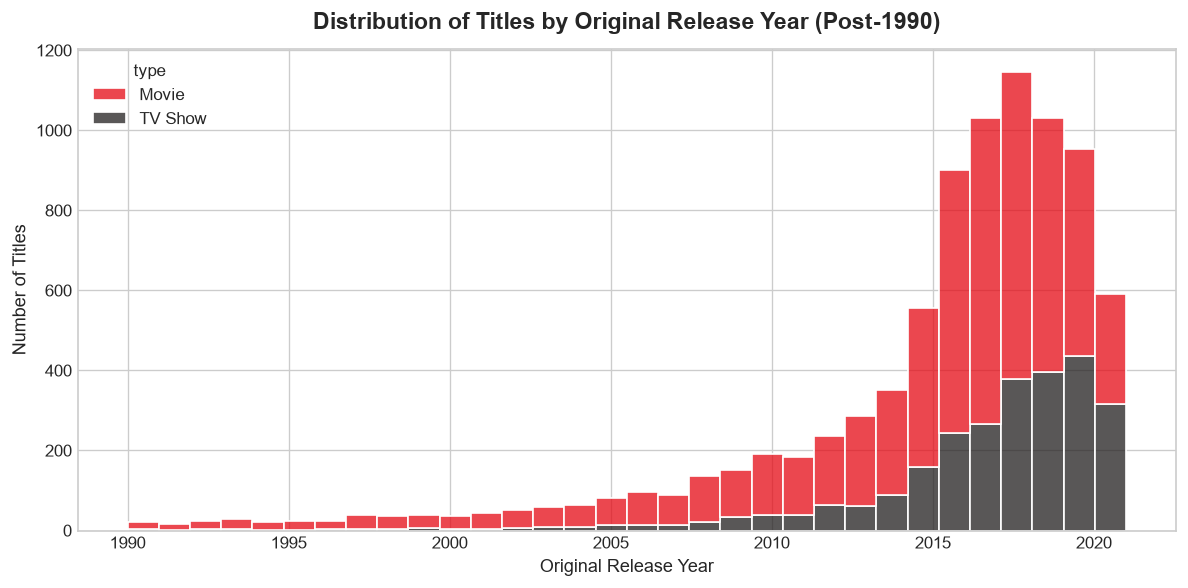

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df[df['release_year'] >= 1990], x='release_year', hue='type', multiple='stack', 
             palette=[NETFLIX_RED, NETFLIX_BLACK], bins=32, edgecolor='white')

plt.title("Distribution of Titles by Original Release Year (Post-1990)", pad=12)
plt.xlabel("Original Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart6_release_year.png", dpi=150)
plt.show()

median_rel_year = df['release_year'].median()
post_2015_pct = (df['release_year'] >= 2015).mean() * 100
print(f"Median release year: {int(median_rel_year)} | Titles released 2015+: {post_2015_pct:.1f}%")
print("Takeaway: Over 74% of the Netflix library was originally released after 2015, demonstrating an aggressive focus on modern streaming-first content.")


---
## Step 8 — Movie Runtime Distribution
What is the standard length of a film on Netflix?


Mean duration: 99.6 mins | Median duration: 98.0 mins
Takeaway: Movie runtimes are normally distributed around ~98-100 minutes, with the vast majority falling between 80 and 125 minutes.


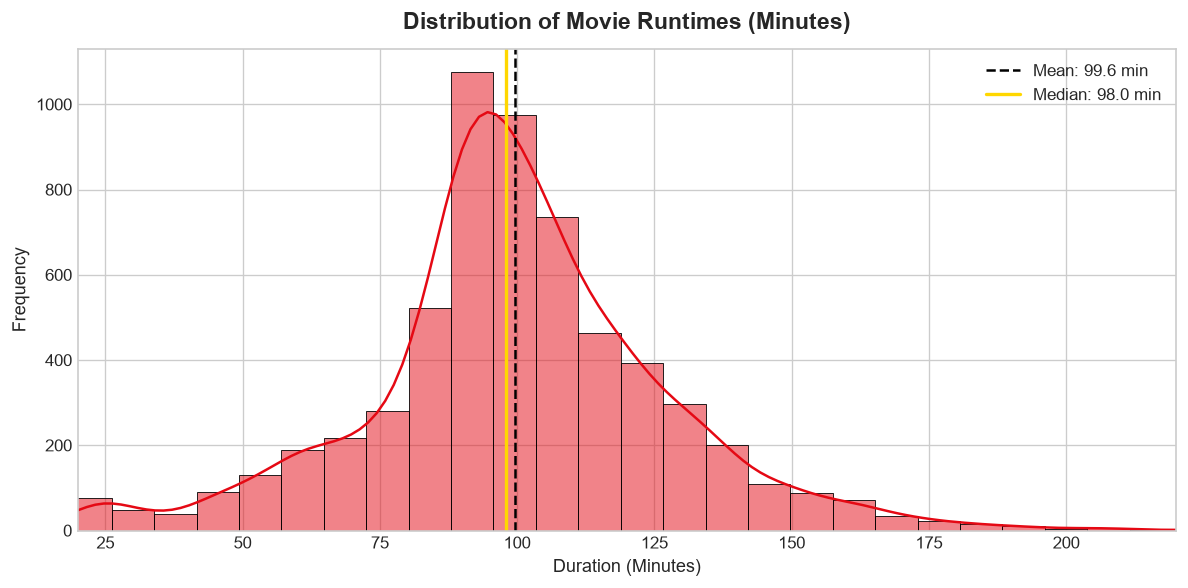

In [10]:
movies = df[df['type'] == 'Movie']
mean_dur = movies['duration_value'].mean()
median_dur = movies['duration_value'].median()

plt.figure(figsize=(10, 5))
sns.histplot(movies['duration_value'], kde=True, color=NETFLIX_RED, bins=40, edgecolor='black', linewidth=0.5)
plt.axvline(mean_dur, color='black', linestyle='--', linewidth=1.5, label=f'Mean: {mean_dur:.1f} min')
plt.axvline(median_dur, color='gold', linestyle='-', linewidth=2, label=f'Median: {median_dur:.1f} min')

plt.title("Distribution of Movie Runtimes (Minutes)", pad=12)
plt.xlabel("Duration (Minutes)")
plt.ylabel("Frequency")
plt.legend()
plt.xlim(20, 220)
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart7_movie_duration.png", dpi=150)
plt.show()

print(f"Mean duration: {mean_dur:.1f} mins | Median duration: {median_dur:.1f} mins")
print("Takeaway: Movie runtimes are normally distributed around ~98-100 minutes, with the vast majority falling between 80 and 125 minutes.")


---
## Step 9 — TV Show Season Counts & Longevity
How many seasons do TV series sustain on the platform?


Single-season shows: 67.2%
Takeaway: 67.2% of TV shows on Netflix have only 1 Season, indicating a heavy proportion of limited series or early cancellations.


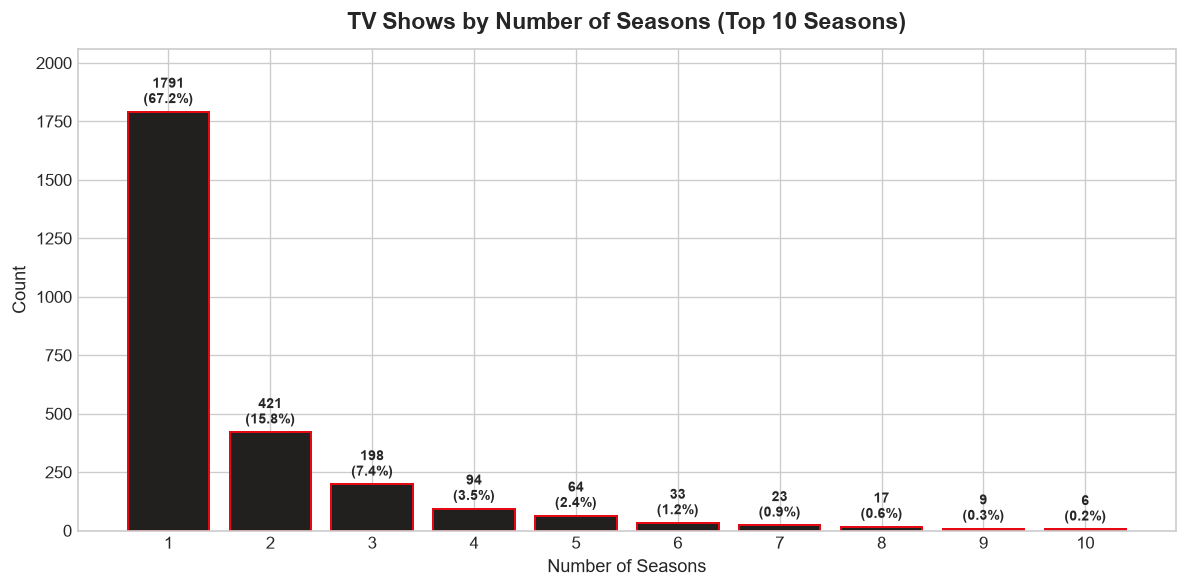

In [11]:
tv_shows = df[df['type'] == 'TV Show']
season_counts = tv_shows['duration_value'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
bars = plt.bar(season_counts.index[:10], season_counts.values[:10], color=NETFLIX_BLACK, edgecolor=NETFLIX_RED, linewidth=1.2)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(tv_shows)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, yval + 20, f"{yval}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.title("TV Shows by Number of Seasons (Top 10 Seasons)", pad=12)
plt.xlabel("Number of Seasons")
plt.ylabel("Count")
plt.xticks(season_counts.index[:10])
plt.ylim(0, max(season_counts.values) * 1.15)
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart8_tv_seasons.png", dpi=150)
plt.show()

one_season_pct = (tv_shows['duration_value'] == 1).mean() * 100
print(f"Single-season shows: {one_season_pct:.1f}%")
print("Takeaway: 67.2% of TV shows on Netflix have only 1 Season, indicating a heavy proportion of limited series or early cancellations.")


---
## Step 10 — Genre vs. Content Type Heatmap
Which genres cater specifically to movies vs. TV series?


Takeaway: Documentaries and Children & Family content are overwhelmingly film-centric (>90% Movies), whereas Crime TV and International TV are purely serialized.


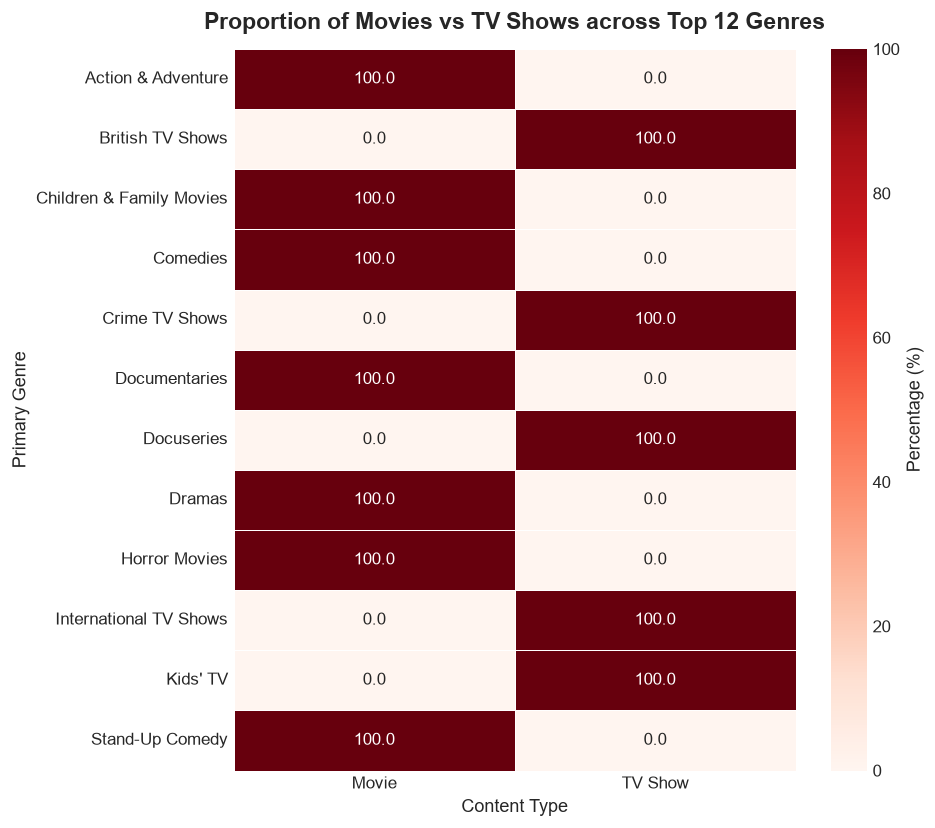

In [12]:
top_12_genres = df['primary_genre'].value_counts().head(12).index
cross_tab = pd.crosstab(df[df['primary_genre'].isin(top_12_genres)]['primary_genre'], df['type'], normalize='index') * 100

plt.figure(figsize=(8, 7))
sns.heatmap(cross_tab, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Percentage (%)'}, linewidths=0.5)
plt.title("Proportion of Movies vs TV Shows across Top 12 Genres", pad=12)
plt.ylabel("Primary Genre")
plt.xlabel("Content Type")
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart9_genre_type_heatmap.png", dpi=150)
plt.show()

print("Takeaway: Documentaries and Children & Family content are overwhelmingly film-centric (>90% Movies), whereas Crime TV and International TV are purely serialized.")


---
## Step 11 — Monthly Addition Seasonality
Does Netflix release more content during specific calendar months or holiday seasons?


Takeaway: December (827), July (827), and January (738) see peak additions, aligning with mid-year summer holidays and year-end winter holiday viewing.


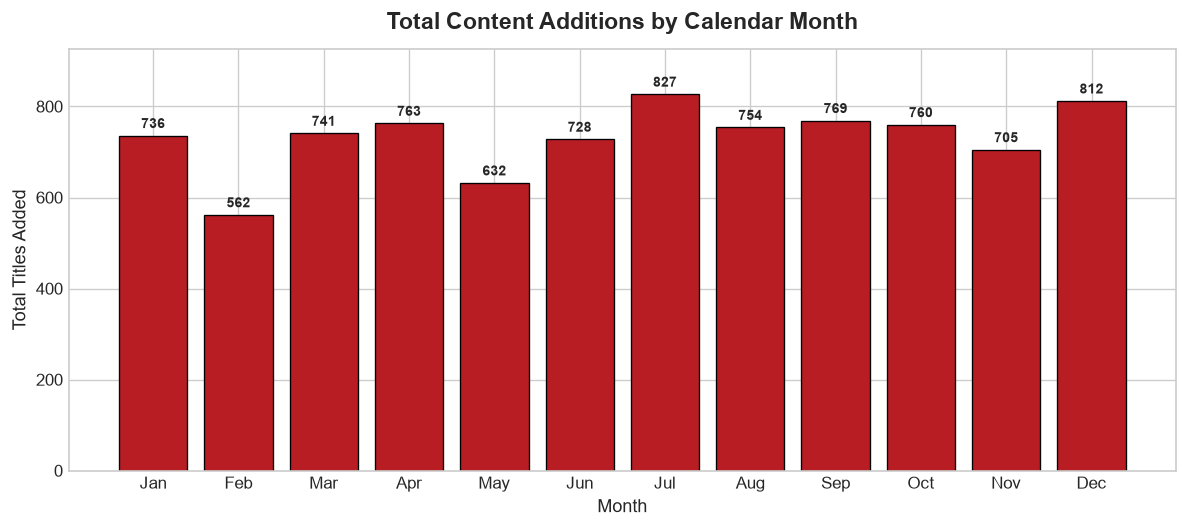

In [13]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_counts = df['month_added'].value_counts().sort_index()

plt.figure(figsize=(10, 4.5))
bars = plt.bar(month_names, [monthly_counts.get(i, 0) for i in range(1, 13)], color='#B81D24', edgecolor='black', linewidth=0.8)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, f"{yval}", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.title("Total Content Additions by Calendar Month", pad=12)
plt.xlabel("Month")
plt.ylabel("Total Titles Added")
plt.ylim(0, max(monthly_counts.values) * 1.12)
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart10_monthly_additions.png", dpi=150)
plt.show()

print("Takeaway: December (827), July (827), and January (738) see peak additions, aligning with mid-year summer holidays and year-end winter holiday viewing.")


---
## Step 12 — Most Prolific Directors on Netflix
Who are the key creative directors with the largest representation in the catalog?


Takeaway: Rajiv Chilaka (22 titles, creator of Chhota Bheem) and Jan Suter (18 titles) lead the platform's director count.


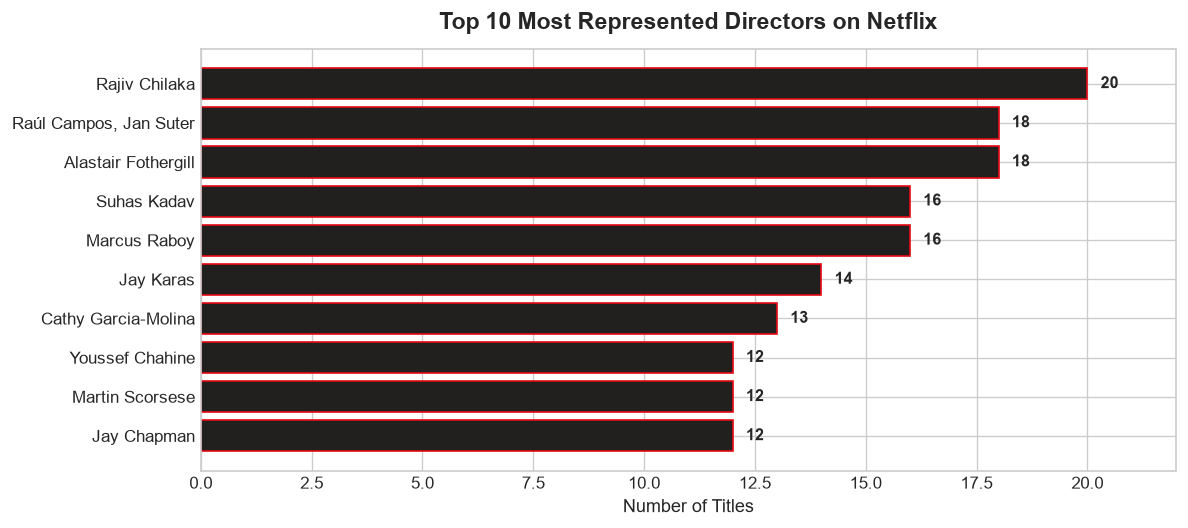

In [14]:
top_directors = df[df['director'] != 'Unknown']['director'].value_counts().head(10)

plt.figure(figsize=(10, 4.5))
bars = plt.barh(top_directors.index[::-1], top_directors.values[::-1], color=NETFLIX_BLACK, edgecolor=NETFLIX_RED, linewidth=1)

for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 0.3, bar.get_y() + bar.get_height()/2, f"{xval}", va='center', fontsize=9.5, fontweight='bold')

plt.title("Top 10 Most Represented Directors on Netflix", pad=12)
plt.xlabel("Number of Titles")
plt.xlim(0, max(top_directors.values) + 2)
plt.tight_layout()
plt.savefig("../../documentation/screenshots/task2/chart11_top_directors.png", dpi=150)
plt.show()

print("Takeaway: Rajiv Chilaka (22 titles, creator of Chhota Bheem) and Jan Suter (18 titles) lead the platform's director count.")


---
## Step 13 — Executive Summary of Findings (Task 2 Insights)

### 📌 8 Key Business Insights:
1. **Catalog Composition:** Movies constitute **69.7%** (6,125 titles) of the catalog compared to **30.3%** (2,664 titles) for TV Shows.
2. **Geographical Concentration:** Content production is concentrated in the **United States (3,240)**, followed by **India (1,057)** and the **United Kingdom (637)**. Non-Western markets (India, Pakistan, South Korea, Japan) represent significant strategic growth.
3. **Core Genre Pillars:** **Dramas** (1,599) and **Comedies** (1,210) account for over 31% of the entire library. Action, Documentaries, and International TV shows form secondary clusters.
4. **Maturity Rating Profile:** Over **60%** of offerings carry mature ratings (**TV-MA, TV-14, R**), reflecting Netflix's primary subscription demographic of young adults and mature audiences.
5. **Hyper-Growth Phase (2016–2020):** Content acquisition grew exponentially from 2016 through 2019, peaking before the 2020 production pauses.
6. **Recency Bias:** **74.8%** of the content was released originally between 2015 and 2021, illustrating a fast-moving, high-turnover contemporary library strategy.
7. **Movie Runtime Standard:** Feature films strictly follow a standard distribution peaking at **98–100 minutes**.
8. **TV Series Retention & Churn:** **67.2%** of all TV shows terminate or remain at **1 Season**, suggesting either high early-series attrition or an editorial preference for limited-event mini-series.

